In [1]:
import os
import pickle

import numpy as np
import pandas as pd
from ultralytics import YOLO
import tqdm
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
BASE_PTH = "results"

model_names = [
    "v2_batch6_merged_furniture_table_chair_model_s",
    "v3_2_table_chair_table_full_v2",
    "v3_2_table_chair_table_top_v2",
    "v3_2_table_chair_table_top_v2_no_occupied_chair"
]

thres = np.arange(0.3, 0.51, 0.05)

datasets = [
    "datasets/v2_batch6/merged_furniture_table_chair/project.yaml",
    "datasets/v3_2/table_chair_table_top_v2/project.yaml",
    "datasets/v3_2/table_chair_table_top_v2_no_occupied_chair_holdout/project.yaml",
]

In [7]:
def eval(model_names: list[str], dataset: str) -> None:

    results = {}
    for model_name in model_names:
        model = YOLO(os.path.join(BASE_PTH, model_name, "weights/best.pt"))
        
        box_mrs = []
        box_mps = []
        box_fs = []

        pose_mrs = []
        pose_mps = []
        pose_fs = []

        for th in tqdm.tqdm(thres):
            metrics = model.val(
                data=dataset,
                task="pose", iou=0.45, conf=th, device=[1], batch=30, classes=np.arange(2), verbose=False)
            box_mrs.append(metrics.box.r)
            box_mps.append(metrics.box.p)
            box_fs.append(metrics.box.f1)

            pose_mrs.append(metrics.pose.r)
            pose_mps.append(metrics.pose.p)
            pose_fs.append(metrics.pose.f1)
        
        results[model_name] = {
            "box_mr": box_mrs,
            "box_mp": box_mps,
            "box_f1": box_fs,
            "pose_mr": pose_mrs,
            "pose_mp": pose_mps,
            "pose_f1": pose_fs
        }

    with open("val_results_v3.pkl", "wb") as f:
        pickle.dump(results, f)

    with open("val_results_v3.pkl", "rb") as f:
        results = pickle.load(f)
        
    class_names = ["chair", "table"]
    for class_idx in range(2):
        plt.figure(figsize=(20, 13))

        plt.suptitle(class_names[class_idx])
        for model_name, model_results in results.items():
            for idx, (metric_name, metric_values) in enumerate(model_results.items()):
                plt.subplot(3, 2, 1 + idx)
                plt.plot(thres, np.stack(metric_values)[:, class_idx], label=model_name)
                plt.grid()
                plt.legend()
                plt.ylabel(metric_name)
                plt.xlabel("Confidence")

    plt.figure(figsize=(16, 9))

    for model_name, model_results in results.items():
        for idx, (metric_name, metric_values) in enumerate(model_results.items()):
            plt.subplot(3, 2, 1 + idx)
            plt.plot(thres, np.stack(metric_values).mean(axis=1), label=model_name)
            plt.grid()
            plt.legend()
            plt.ylabel(metric_name)
            plt.xlabel("Confidence")


In [8]:
eval(model_names, datasets[0])

  0%|          | 0/5 [00:00<?, ?it/s]

Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:1 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
YOLOv8s-pose summary (fused): 187 layers, 11412444 parameters, 0 gradients, 29.4 GFLOPs


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v2_batch6/merged_furniture_table_chair/labels/val.cache... 292 images, 5 backgrounds, 0 corrupt: 100%|██████████| 292/292 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:10<00:00,  1.01s/it]


                   all        292       3858      0.898      0.731      0.826      0.529      0.952      0.774      0.875      0.872
Speed: 1.1ms preprocess, 6.0ms inference, 0.0ms loss, 3.6ms postprocess per image
Results saved to /home/klymy/.pyenv/runs/pose/val602


 20%|██        | 1/5 [00:16<01:05, 16.29s/it]

Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:1 (NVIDIA GeForce GTX 980 Ti, 6078MiB)


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v2_batch6/merged_furniture_table_chair/labels/val.cache... 292 images, 5 backgrounds, 0 corrupt: 100%|██████████| 292/292 [00:00<?, ?it/s]


  0%|          | 0/5 [00:00<?, ?it/s]

Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:1 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
YOLOv8s-pose summary (fused): 187 layers, 11412444 parameters, 0 gradients, 29.4 GFLOPs


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/labels/val.cache... 444 images, 11 backgrounds, 20 corrupt: 100%|██████████| 444/444 [00:00<?, ?it/s]

val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/images/val/108fd94b-b294-49b6-a53d-ff523e7b8fb1.png: ignoring corrupt image/label: negative label values []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/images/val/19e30ed5-1a42-4a9c-a6f8-fad51a4e8cbe.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/images/val/1b381495-0ba1-4bc0-859b-9cc076c77bc0.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/images/val/1d520f58-0288-44b2-9f9d-e8be9edc8afb.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datase

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 15/15 [00:14<00:00,  1.06it/s]


...

val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/labels/val.cache... 444 images, 11 backgrounds, 20 corrupt: 100%|██████████| 444/444 [00:00<?, ?it/s]

val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/images/val/108fd94b-b294-49b6-a53d-ff523e7b8fb1.png: ignoring corrupt image/label: negative label values []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/images/val/19e30ed5-1a42-4a9c-a6f8-fad51a4e8cbe.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/images/val/1b381495-0ba1-4bc0-859b-9cc076c77bc0.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2/images/val/1d520f58-0288-44b2-9f9d-e8be9edc8afb.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datase


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 15/15 [00:12<00:00,  1.19it/s]


                   all        424       6985       0.92      0.581      0.759      0.583      0.958      0.606      0.789      0.786
Speed: 0.9ms preprocess, 6.0ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /home/klymy/.pyenv/runs/pose/val581


100%|██████████| 5/5 [06:05<00:00, 73.00s/it]


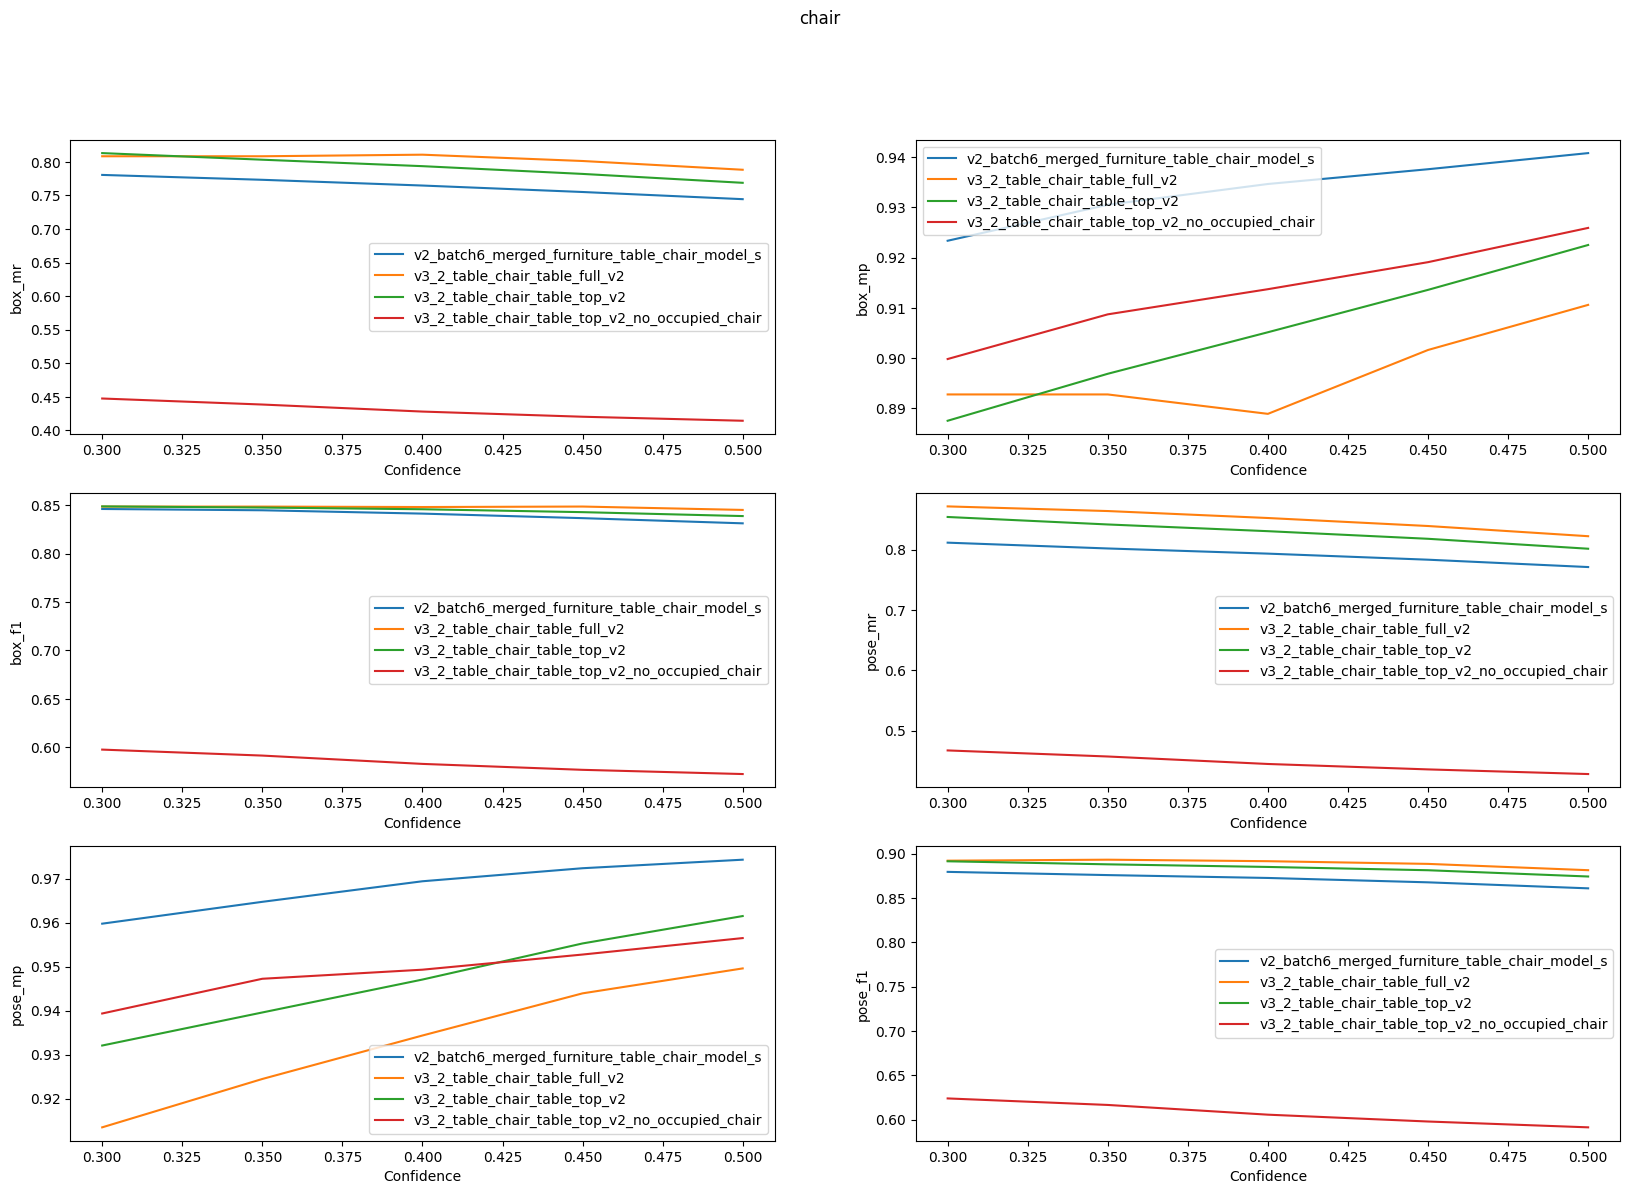

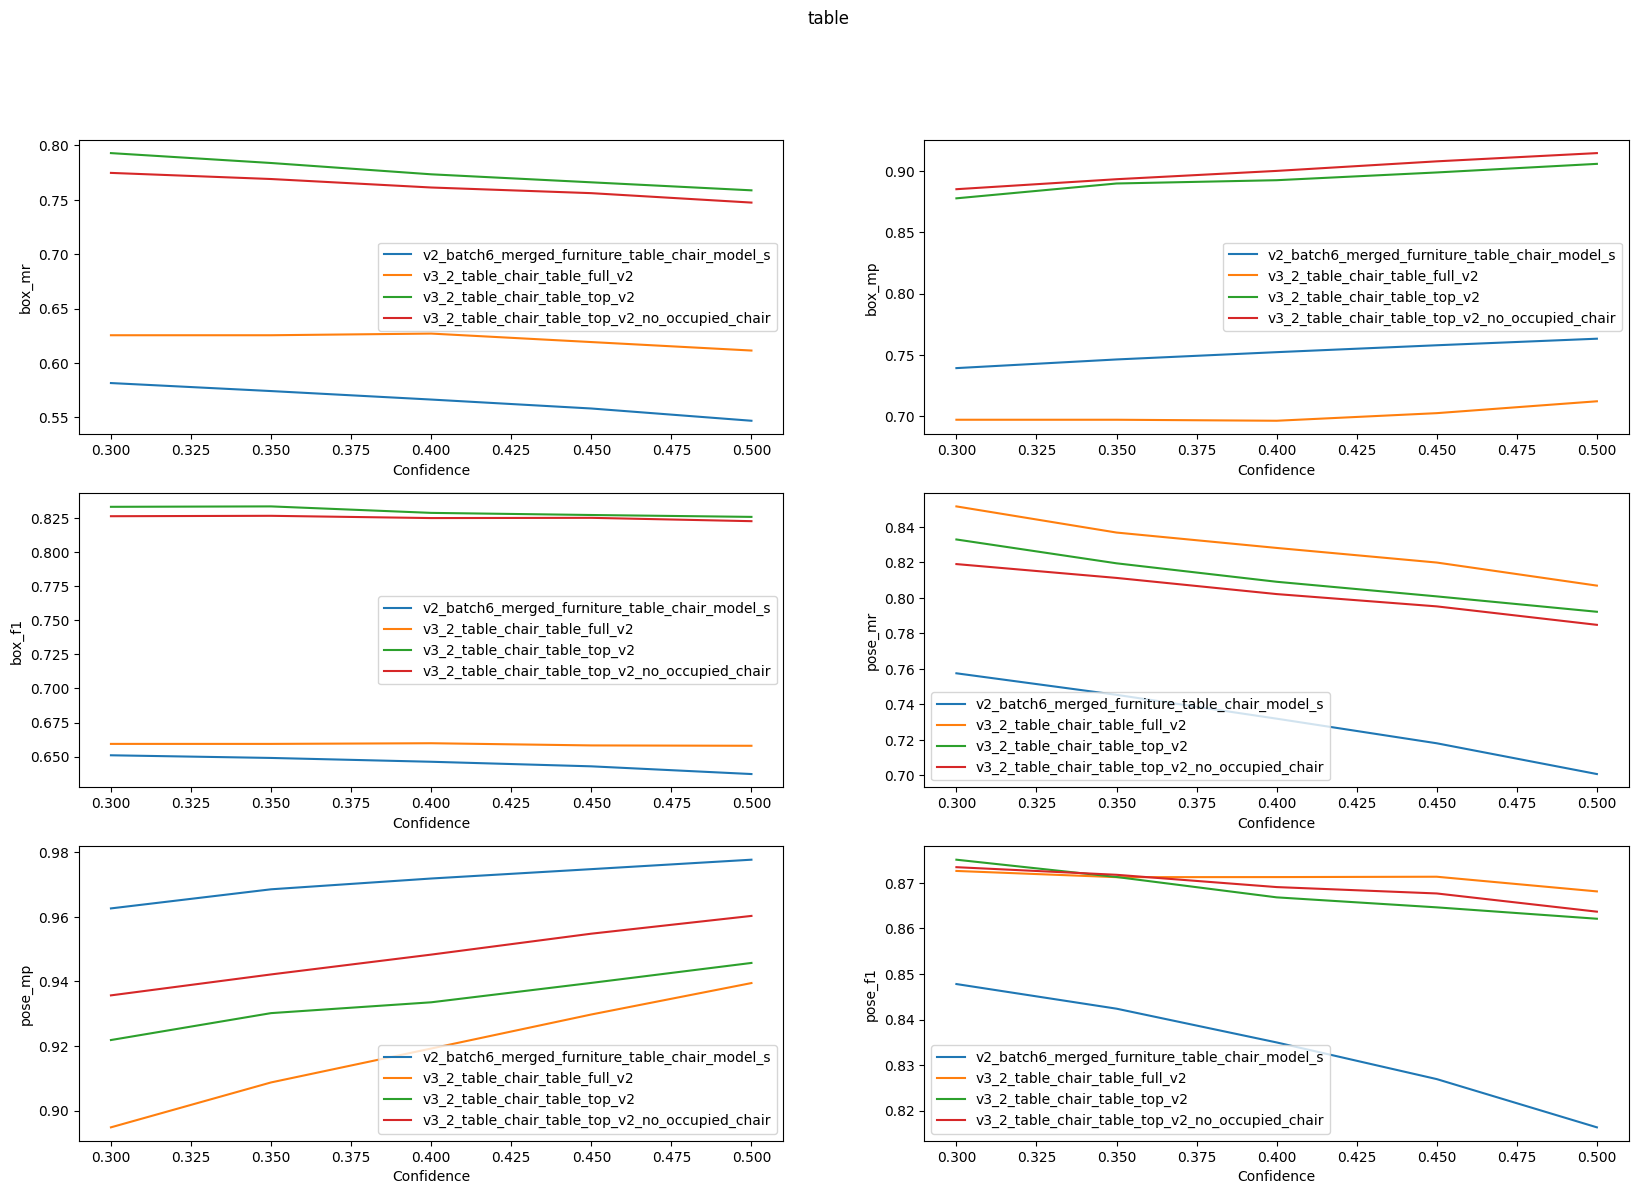

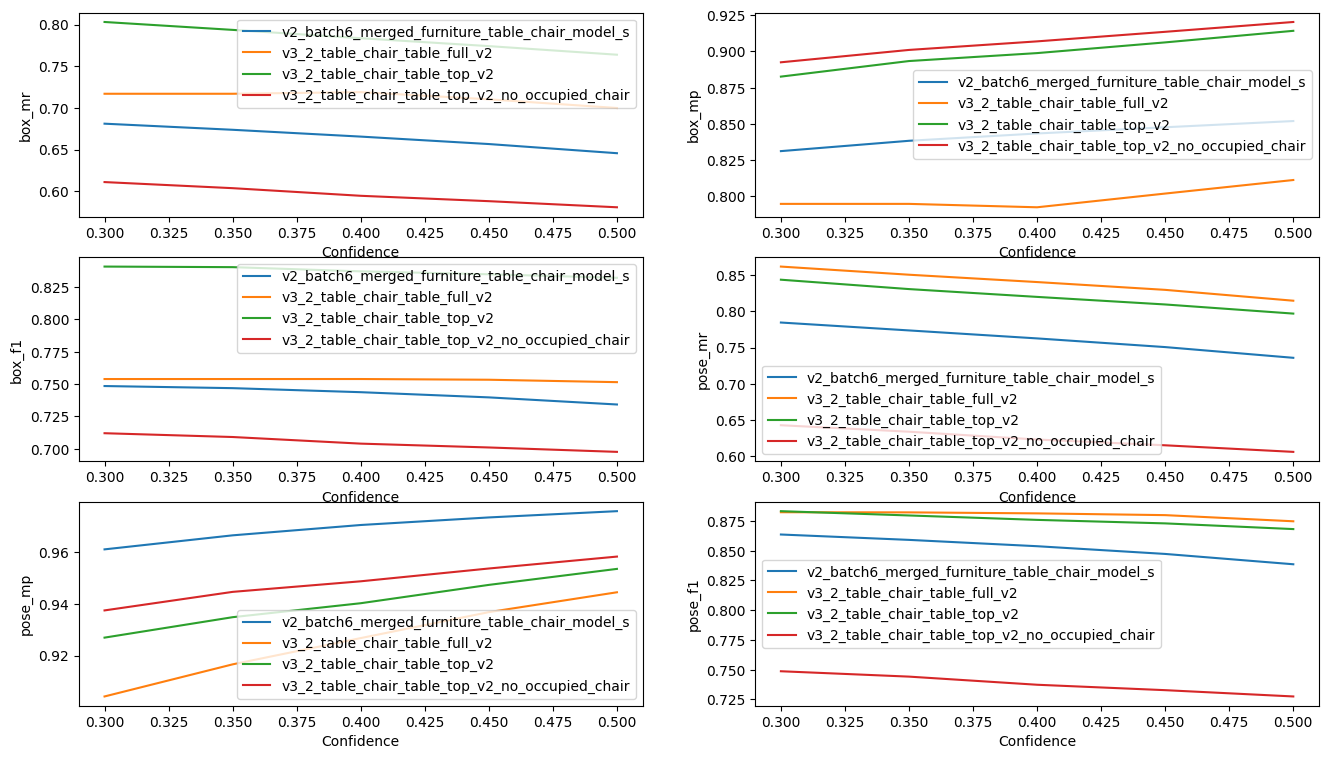

In [ ]:
eval(model_names, datasets[1])

  0%|          | 0/5 [00:00<?, ?it/s]

Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:1 (NVIDIA GeForce GTX 980 Ti, 6078MiB)


YOLOv8s-pose summary (fused): 187 layers, 11412444 parameters, 0 gradients, 29.4 GFLOPs


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair_holdout/labels/val... 36 images, 0 backgrounds, 0 corrupt: 100%|██████████| 36/36 [00:00<00:00, 572.09it/s]

val: New cache created: /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair_holdout/labels/val.cache


...

 80%|████████  | 4/5 [03:09<00:28, 28.86s/it]

Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:1 (NVIDIA GeForce GTX 980 Ti, 6078MiB)


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair_holdout/labels/val.cache... 36 images, 0 backgrounds, 0 corrupt: 100%|██████████| 36/36 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:01<00:00,  1.52it/s]


                   all         36        271       0.94      0.991      0.979      0.824       0.94      0.991      0.987      0.983
Speed: 2.9ms preprocess, 6.1ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /home/klymy/.pyenv/runs/pose/val601


100%|██████████| 5/5 [05:56<00:00, 71.34s/it]


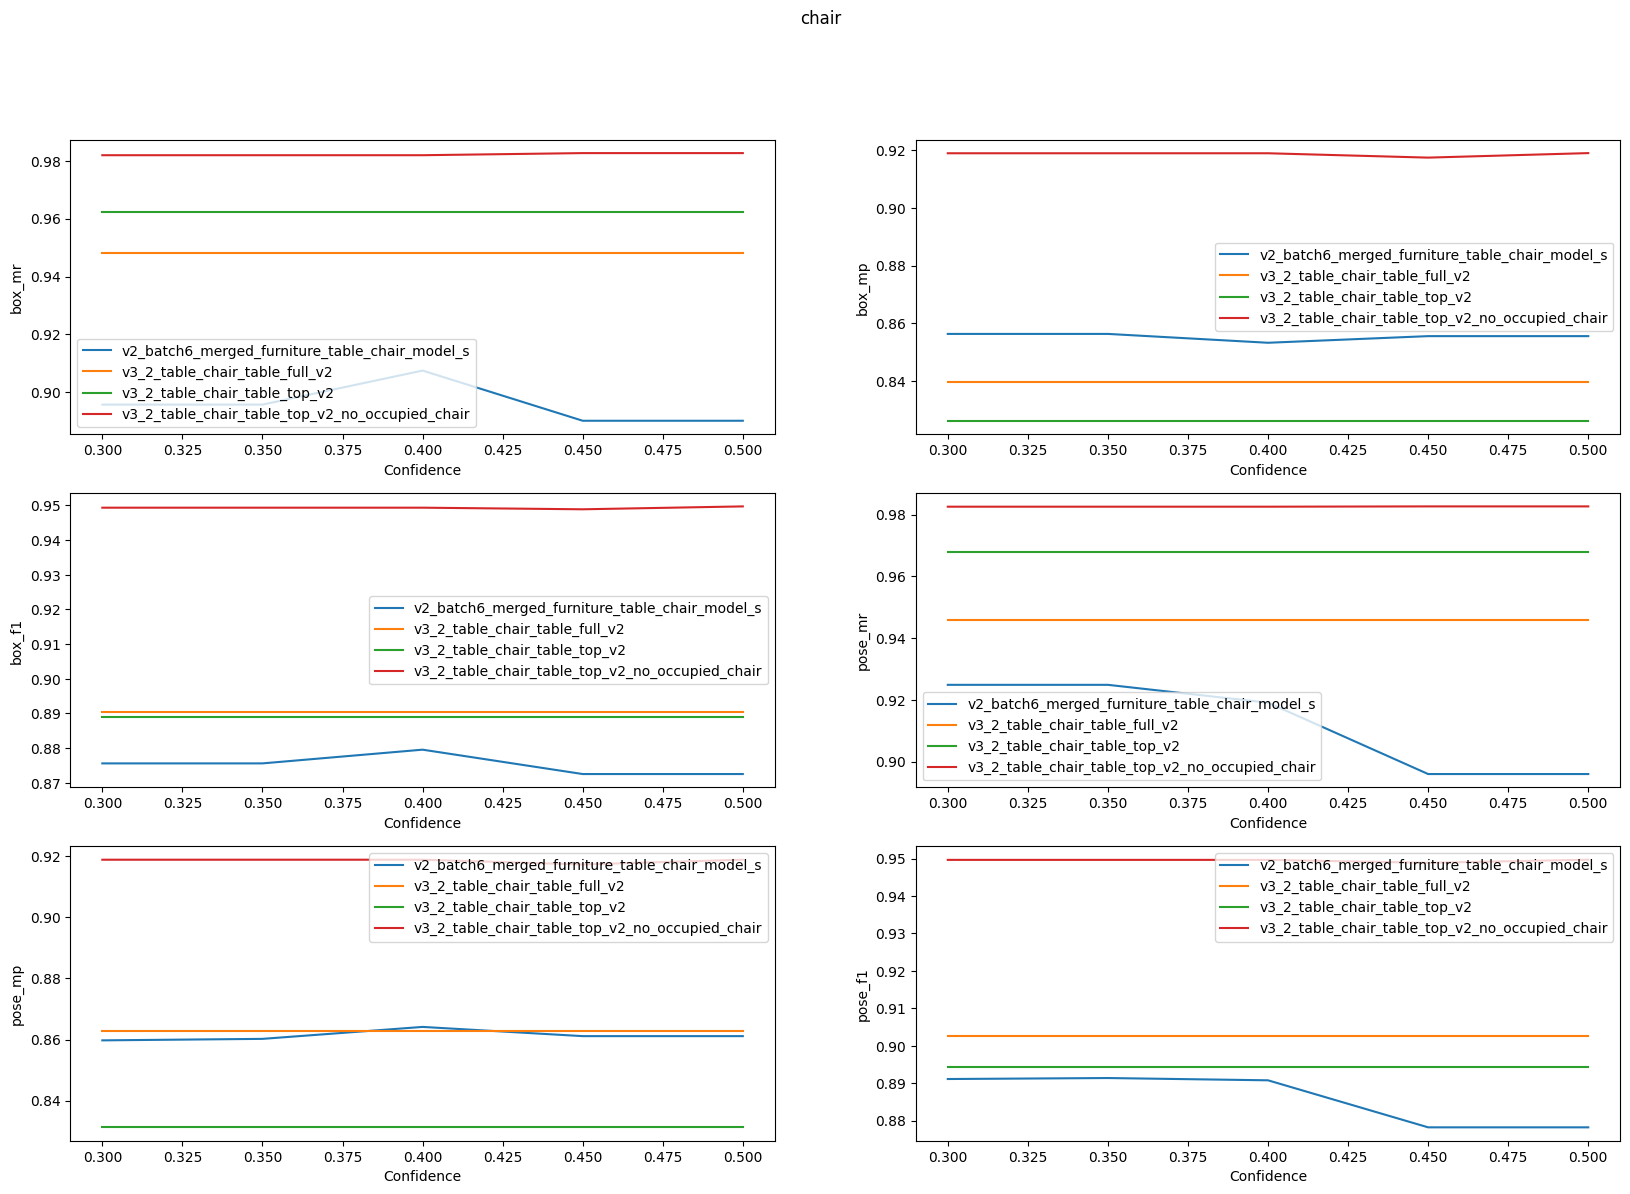

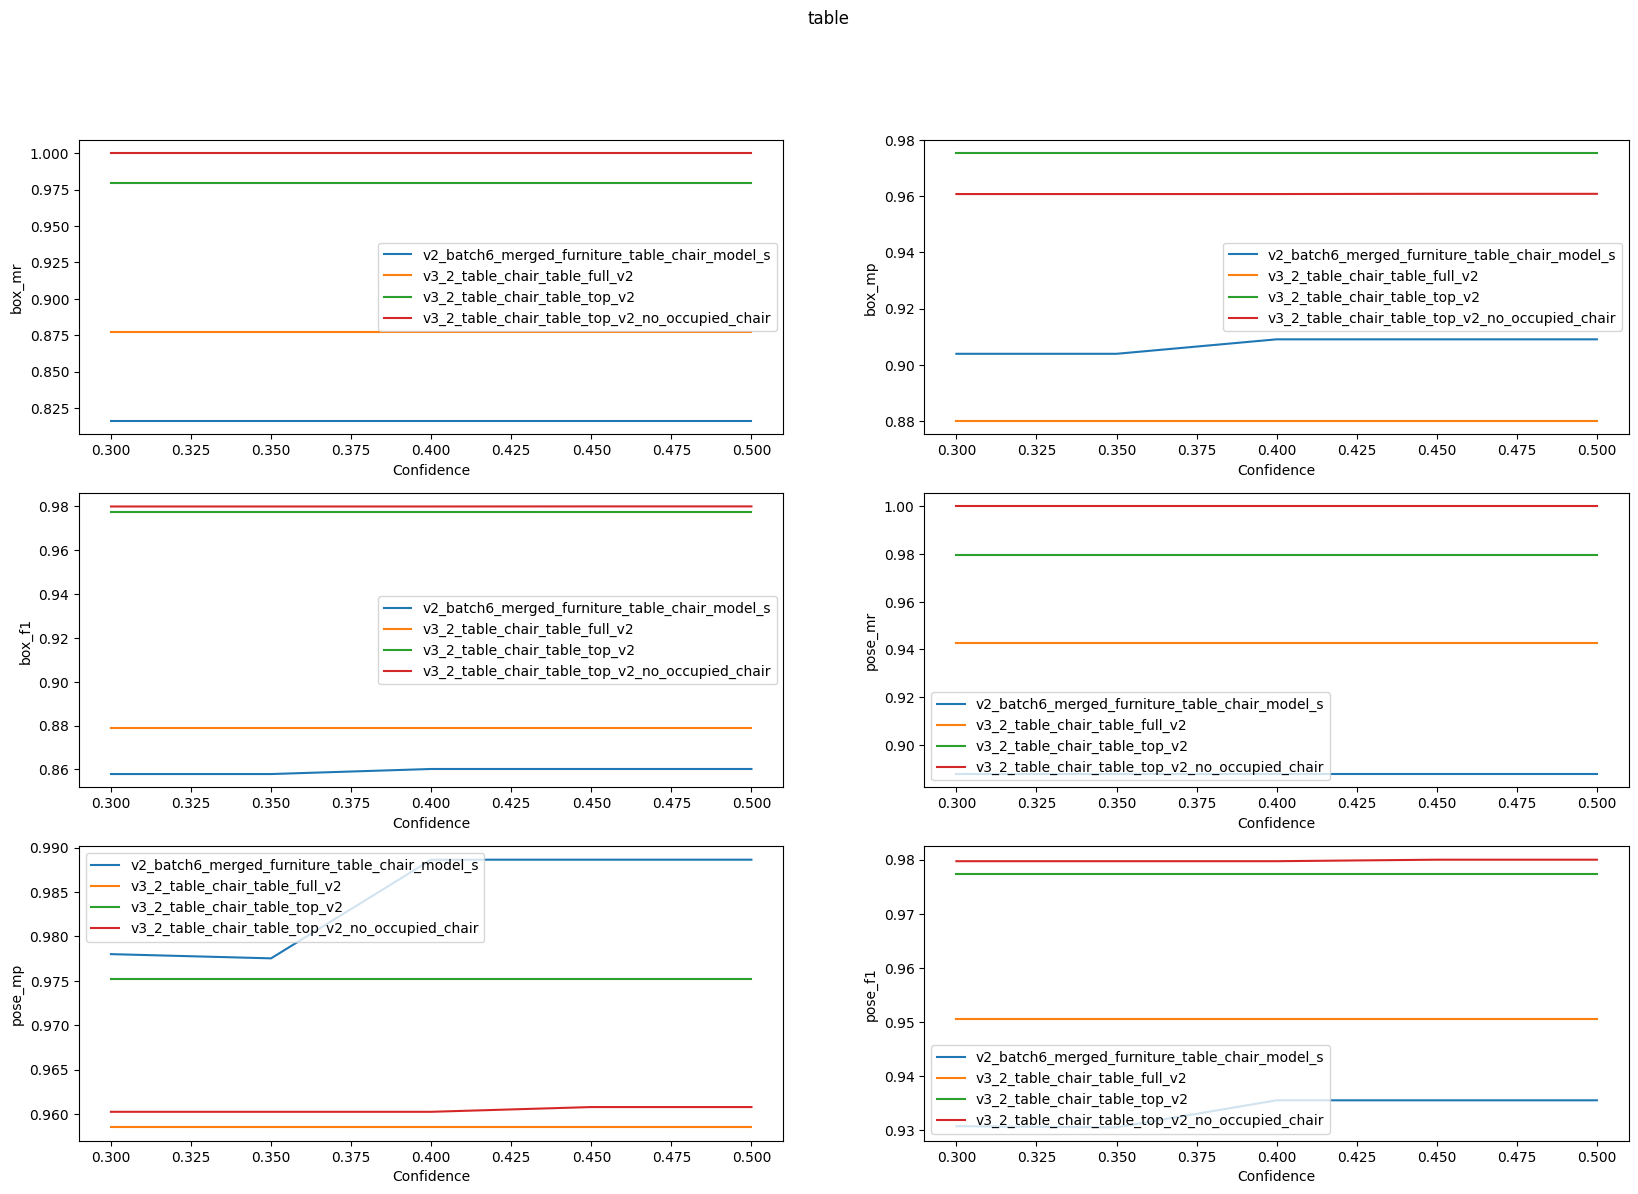

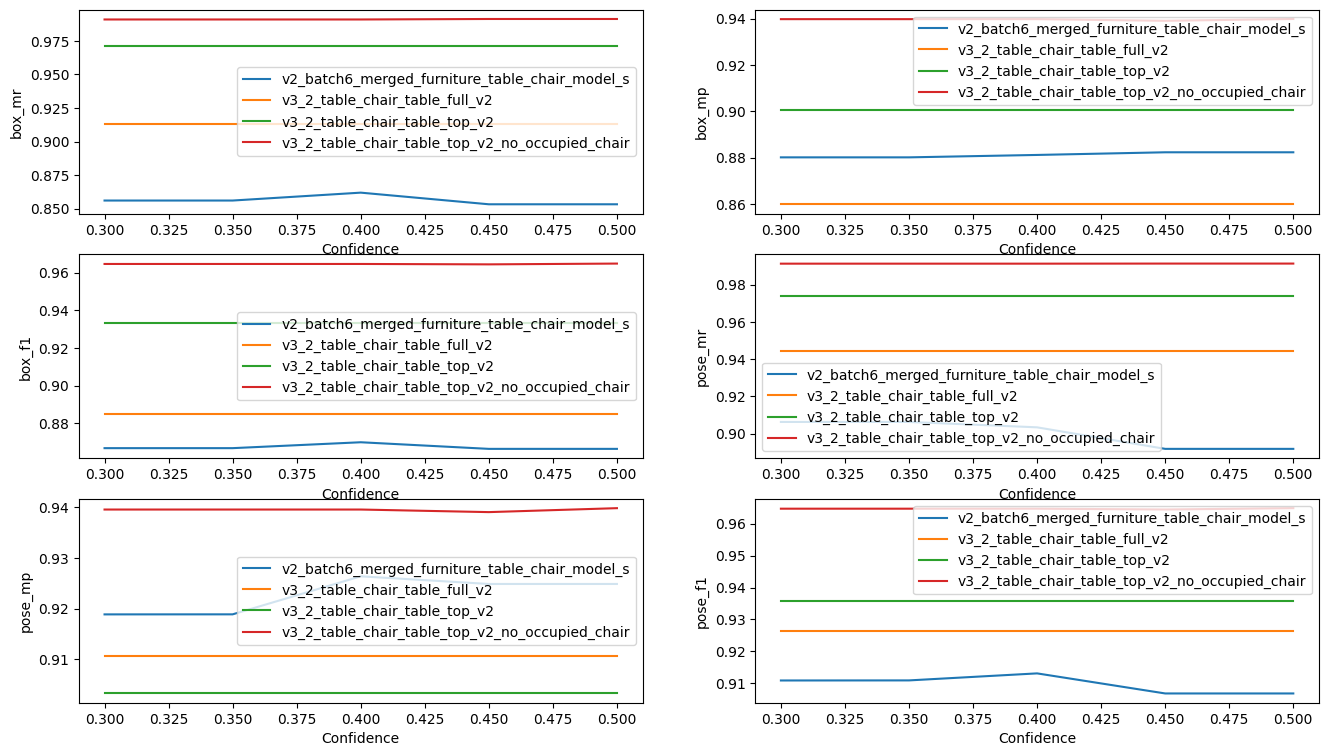

In [14]:
eval(model_names, datasets[2])

In [3]:
results = {}
thres_idx = 0

In [4]:
thres_idx = results_avg = {}
for model_name, model_results in results.items():
    results_avg[model_name] = {}
    for metric_name, metric_values in model_results.items():
        results_avg[model_name][metric_name] = np.mean(metric_values[thres_idx])


pd.DataFrame(results_avg).T

""


In [5]:
results_chair = {}
for model_name, model_results in results.items():
    results_chair[model_name] = {}
    for metric_name, metric_values in model_results.items():
        results_chair[model_name][metric_name] = metric_values[thres_idx][0]


pd.DataFrame(results_chair).T

""


In [6]:
results_table = {}
for model_name, model_results in results.items():
    results_table[model_name] = {}
    for metric_name, metric_values in model_results.items():
        results_table[model_name][metric_name] = metric_values[thres_idx][1]


pd.DataFrame(results_table).T

""


In [22]:
model = YOLO(os.path.join(BASE_PTH, "v3_2_table_chair_table_top_v2_no_occupied_chair", "weights/best.pt"))
print(model.names)

_ = model.val(task="pose", iou=0.45, conf=0.35, device=0, batch=8, data="datasets/v3_2/table_chair_table_top_v2_no_occupied_chair/project.yaml")

print("f1", _.box.f1, _.pose.f1)
print("f1 mean",_.box.f1.mean(), _.pose.f1.mean())

{0: 'chair', 1: 'table'}
Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:0 (NVIDIA GeForce GTX 980 Ti, 6078MiB)


YOLOv8s-pose summary (fused): 187 layers, 11412444 parameters, 0 gradients, 29.4 GFLOPs


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair/labels/val.cache... 444 images, 11 backgrounds, 20 corrupt: 100%|██████████| 444/444 [00:00<?, ?it/s]

val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair/images/val/108fd94b-b294-49b6-a53d-ff523e7b8fb1.png: ignoring corrupt image/label: negative label values []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair/images/val/19e30ed5-1a42-4a9c-a6f8-fad51a4e8cbe.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair/images/val/1b381495-0ba1-4bc0-859b-9cc076c77bc0.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
val: WARNING ⚠️ /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair/images/val/1d520f58-0288-44b2-9f9d-e8be9edc8afb.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates []
va


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 53/53 [00:08<00:00,  5.98it/s]


                   all        424       5093      0.882      0.737      0.827      0.627       0.92      0.769       0.86      0.856
                 chair        392       2784       0.87      0.705      0.804      0.563      0.898      0.728      0.828      0.823
                 table        413       2309      0.893      0.769       0.85       0.69      0.942      0.811      0.893      0.889
Speed: 0.5ms preprocess, 7.4ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /home/klymy/.pyenv/runs/pose/val607
f1 [    0.77857     0.82662] [    0.80397     0.87177]
f1 mean 0.8025973270387978 0.8378696284968101


In [23]:
model = YOLO(os.path.join(BASE_PTH, "v3_2_table_chair_table_top_v2_no_occupied_chair", "weights/best.pt"))
print(model.names)

_ = model.val(task="pose", iou=0.45, conf=0.35, device=0, batch=8, data="datasets/v3_2/table_chair_table_top_v2_no_occupied_chair_holdout/project.yaml")

print("f1", _.box.f1, _.pose.f1)
print("f1 mean",_.box.f1.mean(), _.pose.f1.mean())

{0: 'chair', 1: 'table'}
Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:0 (NVIDIA GeForce GTX 980 Ti, 6078MiB)


YOLOv8s-pose summary (fused): 187 layers, 11412444 parameters, 0 gradients, 29.4 GFLOPs


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair_holdout/labels/val.cache... 36 images, 0 backgrounds, 0 corrupt: 100%|██████████| 36/36 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:02<00:00,  1.78it/s]


                   all         36        271       0.94      0.991       0.98      0.824       0.94      0.991      0.989      0.985
                 chair         35        173      0.919      0.982      0.976      0.787      0.919      0.983      0.984      0.979
                 table         35         98      0.961          1      0.984      0.862       0.96          1      0.994      0.991
Speed: 2.7ms preprocess, 20.6ms inference, 0.0ms loss, 5.0ms postprocess per image
Results saved to /home/klymy/.pyenv/runs/pose/val608
f1 [    0.94935     0.97996] [    0.94967     0.97972]
f1 mean 0.9646543866412512 0.9646970745822997


In [24]:
model = YOLO(os.path.join(BASE_PTH, "v2_batch6_merged_furniture_table_chair_model_s", "weights/best.pt"))
print(model.names)

_ = model.val(task="pose", iou=0.45, conf=0.35, device=0, batch=8, data="datasets/v3_2/table_chair_table_top_v2_no_occupied_chair_holdout/project.yaml")

print("f1", _.box.f1, _.pose.f1)
print("f1 mean",_.box.f1.mean(), _.pose.f1.mean())

{0: 'chair', 1: 'table'}
Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:0 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
YOLOv8s-pose summary (fused): 187 layers, 11412444 parameters, 0 gradients, 29.4 GFLOPs


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v3_2/table_chair_table_top_v2_no_occupied_chair_holdout/labels/val.cache... 36 images, 0 backgrounds, 0 corrupt: 100%|██████████| 36/36 [00:00<?, ?it/s]


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:02<00:00,  2.12it/s]


                   all         36        271       0.88      0.856       0.85      0.632      0.919      0.906      0.912      0.908
                 chair         35        173      0.856      0.896      0.868      0.721       0.86      0.925      0.887       0.88
                 table         35         98      0.904      0.816      0.833      0.542      0.978      0.888      0.938      0.935
Speed: 2.0ms preprocess, 15.8ms inference, 0.1ms loss, 5.0ms postprocess per image
Results saved to /home/klymy/.pyenv/runs/pose/val609
f1 [    0.87559     0.85791] [    0.89136     0.93048]
f1 mean 0.8667501558499224 0.9109230929647119
